
# Rock Physics Software Engineering Project

Gisselle Arteaga, Juan Maya, Jammy Banh

---



<a id="sec1"></a>
## 1. The Conventional RPM Workflow (Figure 1)

The paper's Figure 1 workflow (recreated below) has three parallel inputs feeding into two
combination steps:

* **Mineral composition** (Vclay, Vquartz, Vcalcite, ...) → **VRH model** → moduli of the
  solid matrix (Ks, μs)
* **Porosity and pore geometry** → **Hertz–Mindlin equations** (frame-modulus models) →
  moduli of the dry rock frame (Kfr, μfr) — *this step also needs Ks, μs from VRH*
* **Pressure, temperature, and fluids** → **Batzle–Wang model** → fluid/mixed-fluid bulk
  modulus (Kfluid)

Finally, **Gassmann's equation** combines the dry-frame moduli with the fluid properties to
give the moduli of the *saturated* rock, from which Vp, Vs, and density follow directly.


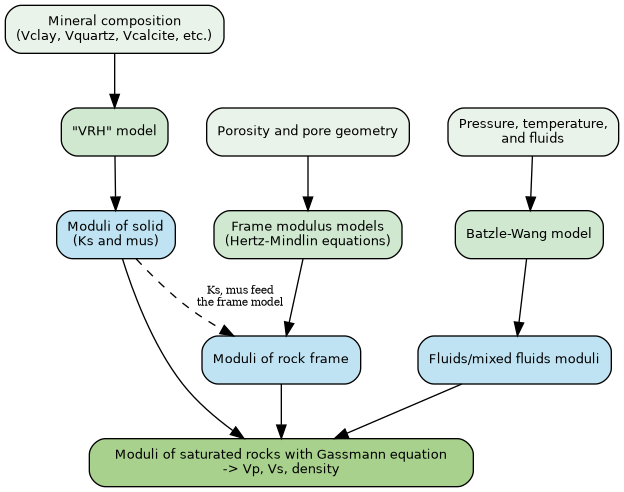

In [ ]:
from IPython.display import Image, display
display(Image(filename="diagrams/workflow_diagram.png"))


<a id="sec2"></a>
## Given Code - Excludes Machine Learning

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Mineral end-member properties (Mavko, Mukerji & Dvorkin, 2009) ---
MINERALS = {
    "quartz":  dict(K=36.6, Mu=45.0, rho=2.65),
    "clay":    dict(K=21.0, Mu=7.0,  rho=2.58),
    "calcite": dict(K=76.8, Mu=32.0, rho=2.71),
}
# Order matches the (VSAND, VSH, VCARB) fraction convention used throughout this notebook
MINERAL_ORDER = ["quartz", "clay", "calcite"]
K_MIN   = np.array([MINERALS[m]["K"]   for m in MINERAL_ORDER])
MU_MIN  = np.array([MINERALS[m]["Mu"]  for m in MINERAL_ORDER])
RHO_MIN = np.array([MINERALS[m]["rho"] for m in MINERAL_ORDER])


def vrh_average(fractions, K, Mu):
    '''Voigt-Reuss-Hill average of bulk (K) and shear (Mu) moduli.

    Parameters
    ----------
    fractions : array_like, shape (..., n_minerals)
        Volume fractions of each mineral end-member (should sum to 1 along the last axis).
    K, Mu : array_like, shape (n_minerals,)
        Bulk and shear modulus of each mineral end-member (GPa).

    Returns
    -------
    K_vrh, Mu_vrh : ndarray
        Voigt-Reuss-Hill averaged bulk and shear modulus (GPa), broadcasting over any
        leading dimensions of `fractions`.
    '''
    fractions = np.asarray(fractions, dtype=float)
    K = np.asarray(K, dtype=float)
    Mu = np.asarray(Mu, dtype=float)

    K_voigt = np.sum(fractions * K, axis=-1)
    K_reuss = 1.0 / np.sum(fractions / K, axis=-1)
    Mu_voigt = np.sum(fractions * Mu, axis=-1)
    Mu_reuss = 1.0 / np.sum(fractions / Mu, axis=-1)

    K_vrh = 0.5 * (K_voigt + K_reuss)
    Mu_vrh = 0.5 * (Mu_voigt + Mu_reuss)
    return K_vrh, Mu_vrh


def solid_density(fractions, rho):
    '''Volumetric (mass-weighted) average mineral density (g/cc).'''
    return np.sum(np.asarray(fractions) * np.asarray(rho), axis=-1)


# quick self-test: a pure mineral should return exactly that mineral's moduli
test_frac = np.array([1.0, 0.0, 0.0])  # pure quartz
Kt, Mut = vrh_average(test_frac, K_MIN, MU_MIN)
assert np.isclose(Kt, 36.6) and np.isclose(Mut, 45.0)
print("VRH self-test passed: pure quartz ->", Kt, "GPa,", Mut, "GPa")

VRH self-test passed: pure quartz -> 36.6 GPa, 45.0 GPa


### 2.3 Effect of lithology on solid-matrix moduli

Sweeping the mixture from pure sand to pure shale (at zero carbonate) shows the Voigt and Reuss bounds bracketing the VRH average, and illustrates why shaly rocks have a softer matrix than clean sands.

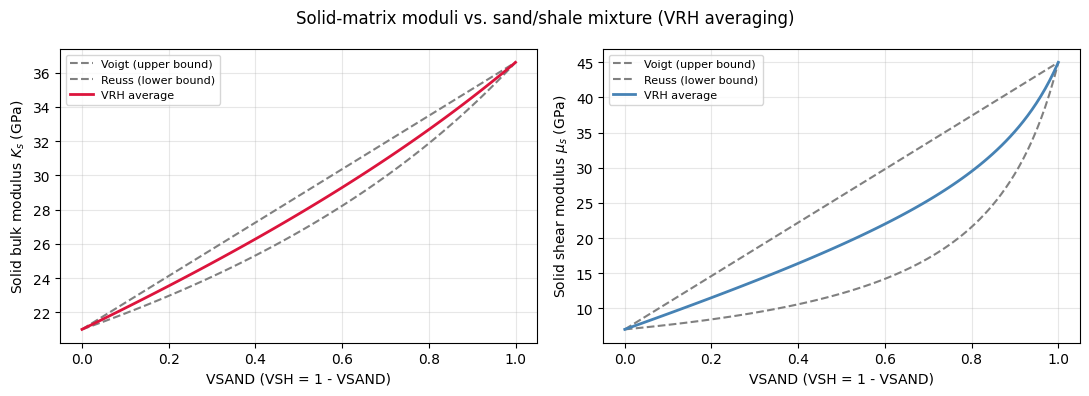

In [ ]:
vsand_sweep = np.linspace(0, 1, 100)
fractions_sweep = np.column_stack([vsand_sweep, 1 - vsand_sweep, np.zeros_like(vsand_sweep)])

K_voigt = np.sum(fractions_sweep * K_MIN, axis=-1)
K_reuss = 1.0 / np.sum(fractions_sweep / K_MIN, axis=-1)
K_vrh, Mu_vrh = vrh_average(fractions_sweep, K_MIN, MU_MIN)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(vsand_sweep, K_voigt, "--", label="Voigt (upper bound)", color="gray")
axes[0].plot(vsand_sweep, K_reuss, "--", label="Reuss (lower bound)", color="gray")
axes[0].plot(vsand_sweep, K_vrh, "-", label="VRH average", color="crimson", linewidth=2)
axes[0].set_xlabel("VSAND (VSH = 1 - VSAND)")
axes[0].set_ylabel("Solid bulk modulus $K_s$ (GPa)")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

Mu_voigt = np.sum(fractions_sweep * MU_MIN, axis=-1)
Mu_reuss = 1.0 / np.sum(fractions_sweep / MU_MIN, axis=-1)
axes[1].plot(vsand_sweep, Mu_voigt, "--", color="gray", label="Voigt (upper bound)")
axes[1].plot(vsand_sweep, Mu_reuss, "--", color="gray", label="Reuss (lower bound)")
axes[1].plot(vsand_sweep, Mu_vrh, "-", color="steelblue", linewidth=2, label="VRH average")
axes[1].set_xlabel("VSAND (VSH = 1 - VSAND)")
axes[1].set_ylabel(r"Solid shear modulus $\mu_s$ (GPa)")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)
plt.suptitle("Solid-matrix moduli vs. sand/shale mixture (VRH averaging)")
plt.tight_layout()
plt.show()

In [ ]:
def solid_poisson_ratio(Ks, Mus):
    '''Poisson's ratio of the solid mineral from its bulk & shear modulus.'''
    return (3 * Ks - 2 * Mus) / (2 * (3 * Ks + Mus))


def hertz_mindlin(Ks, Mus, phi_c, C, gamma, P_MPa):
    '''Hertz-Mindlin dry-frame moduli AT the critical porosity phi_c.

    Parameters
    ----------
    Ks, Mus : solid (mineral) bulk & shear modulus (GPa), from VRH averaging.
    phi_c : critical porosity (fraction, e.g. 0.4).
    C : coordination number (average grain contacts per grain).
    gamma : contact friction/slip coefficient, 0 (frictionless) to 1 (no-slip).
    P_MPa : differential (effective) pressure (MPa).

    Returns
    -------
    K_HM, Mu_HM : Hertz-Mindlin bulk & shear modulus at phi_c (GPa).
    '''
    sigma = solid_poisson_ratio(Ks, Mus)
    P = P_MPa / 1000.0  # MPa -> GPa, so units are consistent with Ks/Mus (GPa)

    K_HM = (C**2 * (1 - phi_c)**2 * Mus**2 / (18 * np.pi**2 * (1 - sigma)**2) * P) ** (1/3)

    coeff = (2 + 3*gamma - sigma*(1 + 3*gamma)) / (5 * (2 - sigma))
    Mu_HM = coeff * (3 * C**2 * (1 - phi_c)**2 * Mus**2 / (2 * np.pi**2 * (1 - sigma)**2) * P) ** (1/3)

    return K_HM, Mu_HM


def modified_hashin_shtrikman_frame(phi, phi_c, Ks, Mus, K_HM, Mu_HM):
    '''Interpolates dry-frame moduli between the solid (phi=0) and Hertz-Mindlin
    (phi=phi_c) endpoints, via the modified lower Hashin-Shtrikman bound
    (paper Eqs. 1-3).
    '''
    phi = np.asarray(phi, dtype=float)
    ratio = np.clip(phi / phi_c, 0.0, 1.0)  # clip: undefined for phi > phi_c (unconsolidated/suspension regime)

    K_fr = (ratio / (K_HM + 4/3*Mus) + (1 - ratio) / (Ks + 4/3*Mus)) ** (-1) - 4/3*Mus

    xi = (Mus / 6.0) * (9*Ks + 8*Mus) / (Ks + 2*Mus)
    Mu_fr = (ratio / (Mu_HM + xi) + (1 - ratio) / (Mus + xi)) ** (-1) - xi

    return K_fr, Mu_fr


# --- numerical verification of the two limiting cases ---
Ks_demo, Mus_demo = 33.6, 24.6   # representative sand-dominated solid moduli
K_HM_demo, Mu_HM_demo = hertz_mindlin(Ks_demo, Mus_demo, phi_c=0.4, C=7, gamma=0.3, P_MPa=30)
print(f"K_HM = {K_HM_demo:.3f} GPa, Mu_HM = {Mu_HM_demo:.3f} GPa  (at phi_c=0.4, P=30 MPa)")

K_at_0, Mu_at_0 = modified_hashin_shtrikman_frame(0.0, 0.4, Ks_demo, Mus_demo, K_HM_demo, Mu_HM_demo)
K_at_c, Mu_at_c = modified_hashin_shtrikman_frame(0.4, 0.4, Ks_demo, Mus_demo, K_HM_demo, Mu_HM_demo)
print(f"K_fr(phi=0)    = {K_at_0:.3f} GPa  (should equal Ks = {Ks_demo})")
print(f"K_fr(phi=phi_c)= {K_at_c:.3f} GPa  (should equal K_HM = {K_HM_demo:.3f})")
assert np.isclose(K_at_0, Ks_demo) and np.isclose(K_at_c, K_HM_demo)
print("Endpoint checks passed.")

K_HM = 1.419 GPa, Mu_HM = 1.191 GPa  (at phi_c=0.4, P=30 MPa)
K_fr(phi=0)    = 33.600 GPa  (should equal Ks = 33.6)
K_fr(phi=phi_c)= 1.419 GPa  (should equal K_HM = 1.419)
Endpoint checks passed.


### 3.4 Frame moduli vs. porosity, and sensitivity to pressure and contact friction

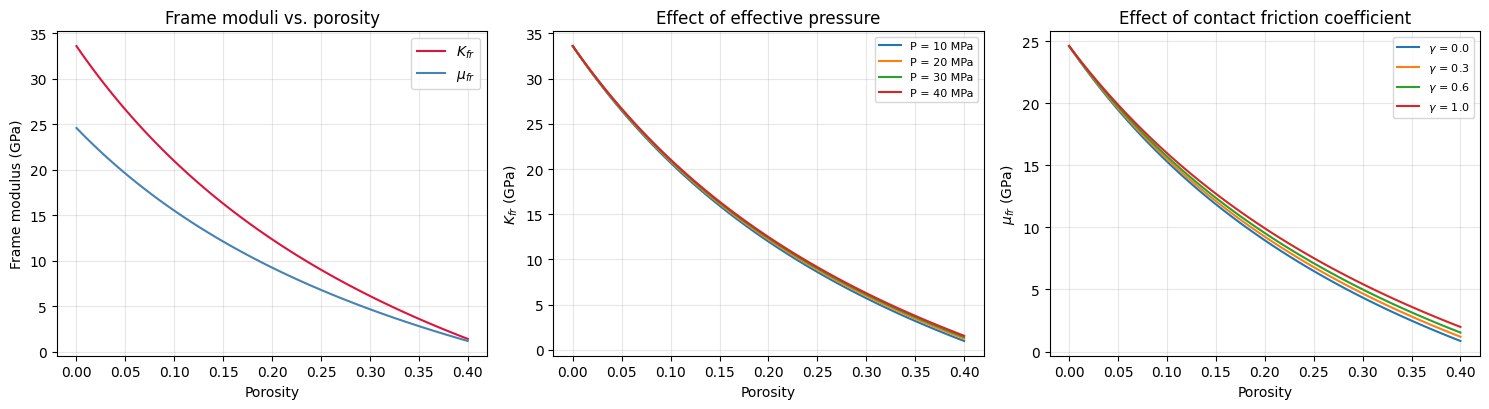

In [ ]:
phi_range = np.linspace(0, 0.4, 100)
K_fr_curve, Mu_fr_curve = modified_hashin_shtrikman_frame(
    phi_range, 0.4, Ks_demo, Mus_demo, K_HM_demo, Mu_HM_demo
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

axes[0].plot(phi_range, K_fr_curve, label=r"$K_{fr}$", color="crimson")
axes[0].plot(phi_range, Mu_fr_curve, label=r"$\mu_{fr}$", color="steelblue")
axes[0].set_xlabel("Porosity")
axes[0].set_ylabel("Frame modulus (GPa)")
axes[0].set_title("Frame moduli vs. porosity")
axes[0].legend()
axes[0].grid(alpha=0.3)

for P in [10, 20, 30, 40]:
    K_HM_p, Mu_HM_p = hertz_mindlin(Ks_demo, Mus_demo, 0.4, 7, 0.3, P)
    K_fr_p, _ = modified_hashin_shtrikman_frame(phi_range, 0.4, Ks_demo, Mus_demo, K_HM_p, Mu_HM_p)
    axes[1].plot(phi_range, K_fr_p, label=f"P = {P} MPa")
axes[1].set_xlabel("Porosity")
axes[1].set_ylabel(r"$K_{fr}$ (GPa)")
axes[1].set_title("Effect of effective pressure")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

for gamma in [0.0, 0.3, 0.6, 1.0]:
    K_HM_g, Mu_HM_g = hertz_mindlin(Ks_demo, Mus_demo, 0.4, 7, gamma, 30)
    _, Mu_fr_g = modified_hashin_shtrikman_frame(phi_range, 0.4, Ks_demo, Mus_demo, K_HM_g, Mu_HM_g)
    axes[2].plot(phi_range, Mu_fr_g, label=rf"$\gamma$ = {gamma}")
axes[2].set_xlabel("Porosity")
axes[2].set_ylabel(r"$\mu_{fr}$ (GPa)")
axes[2].set_title("Effect of contact friction coefficient")
axes[2].legend(fontsize=8)
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
K_BRINE, RHO_BRINE = 2.80, 1.03   # GPa, g/cc
K_OIL, RHO_OIL = 0.90, 0.85       # GPa, g/cc


def fluid_properties(sw, K_w=K_BRINE, rho_w=RHO_BRINE, K_hc=K_OIL, rho_hc=RHO_OIL):
    '''Effective fluid bulk modulus and density from water saturation, via Wood's equation.

    Parameters
    ----------
    sw : array_like
        Water saturation (fraction, 0-1).
    K_w, rho_w : brine bulk modulus (GPa) and density (g/cc).
    K_hc, rho_hc : hydrocarbon bulk modulus (GPa) and density (g/cc).

    Returns
    -------
    K_fluid, rho_fluid : effective mixed-fluid bulk modulus (GPa) and density (g/cc).
    '''
    sw = np.asarray(sw, dtype=float)
    K_fluid = 1.0 / (sw / K_w + (1 - sw) / K_hc)
    rho_fluid = sw * rho_w + (1 - sw) * rho_hc
    return K_fluid, rho_fluid


# sanity check: pure brine and pure oil recover the endmember properties exactly
Kf0, rf0 = fluid_properties(0.0)
Kf1, rf1 = fluid_properties(1.0)
assert np.isclose(Kf0, K_OIL) and np.isclose(Kf1, K_BRINE)
print(f"Sw=0 (pure oil):   K_fluid={Kf0:.3f} GPa, rho_fluid={rf0:.3f} g/cc")
print(f"Sw=1 (pure brine): K_fluid={Kf1:.3f} GPa, rho_fluid={rf1:.3f} g/cc")

Sw=0 (pure oil):   K_fluid=0.900 GPa, rho_fluid=0.850 g/cc
Sw=1 (pure brine): K_fluid=2.800 GPa, rho_fluid=1.030 g/cc


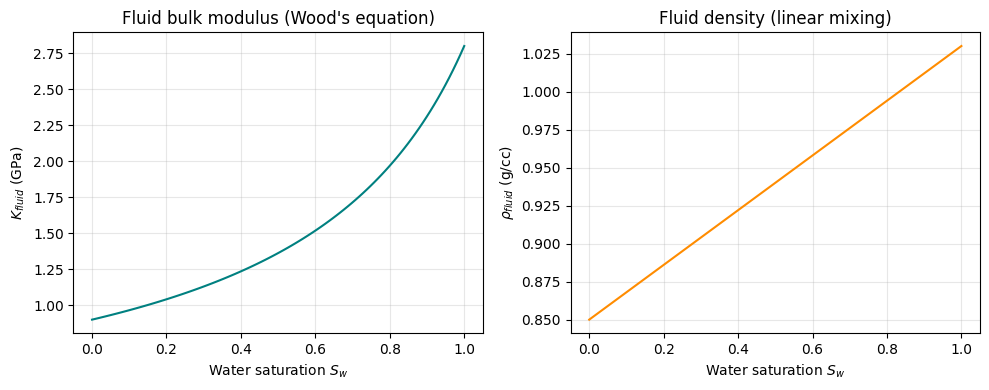

Note the strongly non-linear drop in K_fluid as soon as a little gas/oil enters the pore space -- Wood's equation is dominated by the softest phase (harmonic averaging).


In [ ]:
sw_sweep = np.linspace(0, 1, 100)
K_fluid_sweep, rho_fluid_sweep = fluid_properties(sw_sweep)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(sw_sweep, K_fluid_sweep, color="teal")
axes[0].set_xlabel(r"Water saturation $S_w$")
axes[0].set_ylabel(r"$K_{fluid}$ (GPa)")
axes[0].set_title("Fluid bulk modulus (Wood's equation)")
axes[0].grid(alpha=0.3)

axes[1].plot(sw_sweep, rho_fluid_sweep, color="darkorange")
axes[1].set_xlabel(r"Water saturation $S_w$")
axes[1].set_ylabel(r"$\rho_{fluid}$ (g/cc)")
axes[1].set_title("Fluid density (linear mixing)")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()
print("Note the strongly non-linear drop in K_fluid as soon as a little gas/oil enters the "
      "pore space -- Wood's equation is dominated by the softest phase (harmonic averaging).")

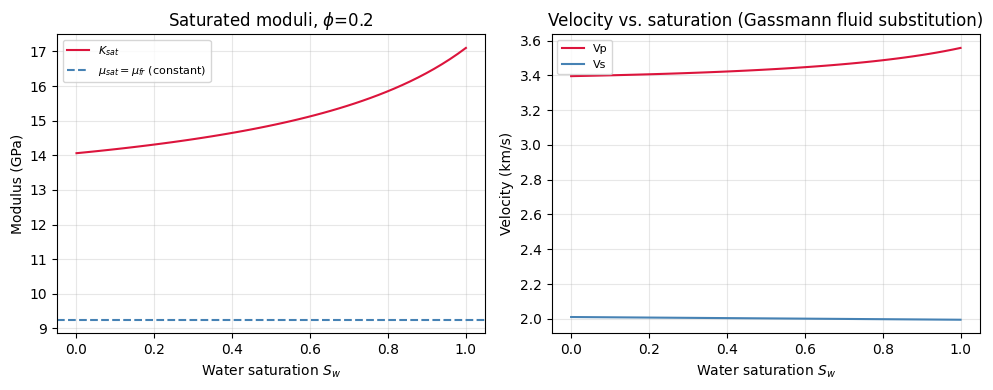

As expected from Gassmann's theory: Vp rises with Sw (stiffer brine vs. oil), while Vs is essentially flat (shear modulus is fluid-independent) -- this is exactly the fluid sensitivity mechanism quantitative seismic interpretation relies on.


In [ ]:
def gassmann_saturation(K_fr, Mu_fr, K_mineral, K_fluid, phi):
    '''Gassmann fluid substitution: dry-frame moduli -> fluid-saturated moduli.

    Parameters
    ----------
    K_fr, Mu_fr : dry-frame bulk & shear modulus (GPa), from Section 3.
    K_mineral : solid mineral bulk modulus (GPa), from Section 2 (VRH).
    K_fluid : effective fluid bulk modulus (GPa), from Section 4 (Wood's equation).
    phi : porosity (fraction).

    Returns
    -------
    K_sat, Mu_sat : saturated bulk & shear modulus (GPa). Mu_sat == Mu_fr by
    Gassmann's shear-modulus-unaffected-by-fluid assumption.
    '''
    phi = np.asarray(phi, dtype=float)
    K_sat = K_fr + (1 - K_fr / K_mineral)**2 / (
        phi / K_fluid + (1 - phi) / K_mineral - K_fr / K_mineral**2
    )
    Mu_sat = Mu_fr
    return K_sat, Mu_sat


def bulk_density(phi, rho_mineral, rho_fluid):
    '''Saturated bulk density (g/cc): volumetric mix of solid and fluid.'''
    return (1 - phi) * rho_mineral + phi * rho_fluid


def elastic_velocities(K_sat, Mu_sat, rho_bulk):
    '''Vp, Vs (km/s) from saturated moduli (GPa) and bulk density (g/cc).'''
    Vp = np.sqrt((K_sat + 4/3 * Mu_sat) / rho_bulk)
    Vs = np.sqrt(Mu_sat / rho_bulk)
    return Vp, Vs


# --- demonstration: fluid substitution at fixed frame, varying Sw ---
phi_demo = 0.20
K_fr_demo, Mu_fr_demo = modified_hashin_shtrikman_frame(
    phi_demo, 0.4, Ks_demo, Mus_demo, K_HM_demo, Mu_HM_demo
)
sw_demo = np.linspace(0, 1, 50)
K_fluid_demo, rho_fluid_demo = fluid_properties(sw_demo)
K_sat_demo, Mu_sat_demo = gassmann_saturation(K_fr_demo, Mu_fr_demo, Ks_demo, K_fluid_demo, phi_demo)
rho_bulk_demo = bulk_density(phi_demo, RHO_MIN[0], rho_fluid_demo)  # quartz-ish solid density for demo
Vp_demo, Vs_demo = elastic_velocities(K_sat_demo, Mu_sat_demo, rho_bulk_demo)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(sw_demo, K_sat_demo, color="crimson", label=r"$K_{sat}$")
axes[0].axhline(Mu_fr_demo, color="steelblue", linestyle="--", label=r"$\mu_{sat}=\mu_{fr}$ (constant)")
axes[0].set_xlabel(r"Water saturation $S_w$")
axes[0].set_ylabel("Modulus (GPa)")
axes[0].set_title(f"Saturated moduli, $\\phi$={phi_demo}")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

axes[1].plot(sw_demo, Vp_demo, color="crimson", label="Vp")
axes[1].plot(sw_demo, Vs_demo, color="steelblue", label="Vs")
axes[1].set_xlabel(r"Water saturation $S_w$")
axes[1].set_ylabel("Velocity (km/s)")
axes[1].set_title("Velocity vs. saturation (Gassmann fluid substitution)")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()
print("As expected from Gassmann's theory: Vp rises with Sw (stiffer brine vs. oil), "
      "while Vs is essentially flat (shear modulus is fluid-independent) -- this is exactly "
      "the fluid sensitivity mechanism quantitative seismic interpretation relies on.")


<a id="sec6"></a>
## 6. The Complete Forward Model

We now chain Sections 2–5 into a single function, `rock_physics_forward_model`, that takes
exactly the inputs a well-log dataset provides — lithology fractions, porosity, water
saturation, and differential pressure — and returns Vp, Vs, and bulk density. This *is* the
paper's Figure 1 workflow, end to end, implemented from first principles.

One modeling choice not specified in the two-page paper: **how to combine the per-lithology
Hertz–Mindlin parameters** ($\phi_c, C, \gamma$ — paper Table 1, reproduced in Section 7) for
a rock that is a *mixture* of shale, sand, and carbonate, rather than a pure end-member. We
use a **linear, volume-fraction-weighted average** of each parameter — a simple, explicit,
clearly-stated assumption that reduces correctly to the pure-lithology parameters at the
mixture's corners, and is standard practice for continuous multi-lithology rock-physics
models when a paper does not specify otherwise.


In [ ]:
# --- Table 1 of the reference paper: optimized Hertz-Mindlin parameters per lithology ---
LITHOLOGY_PARAMS = {
    #              phi_c    C      gamma
    "shale":     dict(phi_c=0.33, C=2.0, gamma=0.56),
    "sand":      dict(phi_c=0.42, C=6.7, gamma=0.01),
    "carbonate": dict(phi_c=0.40, C=6.7, gamma=0.64),
}
LITHOLOGY_ORDER = ["sand", "shale", "carbonate"]  # matches (VSAND, VSH, VCARB) convention


def effective_hm_parameters(vsand, vsh, vcarb):
    '''Volume-fraction-weighted average of phi_c, C, gamma across the three lithology
    end-members (Table 1). Explicit modeling choice -- see Section 6 discussion.
    '''
    fracs = {"sand": vsand, "shale": vsh, "carbonate": vcarb}
    phi_c = sum(fracs[l] * LITHOLOGY_PARAMS[l]["phi_c"] for l in LITHOLOGY_ORDER)
    C = sum(fracs[l] * LITHOLOGY_PARAMS[l]["C"] for l in LITHOLOGY_ORDER)
    gamma = sum(fracs[l] * LITHOLOGY_PARAMS[l]["gamma"] for l in LITHOLOGY_ORDER)
    return phi_c, C, gamma


def rock_physics_forward_model(vsh, vsand, vcarb, phi, sw, pd_mpa):
    '''Full theoretical rock-physics forward model (paper Figure 1), from scratch.

    Parameters
    ----------
    vsh, vsand, vcarb : lithology volume fractions (should sum to 1).
    phi : porosity (fraction).
    sw : water saturation (fraction).
    pd_mpa : differential (effective) pressure (MPa).

    Returns
    -------
    dict with keys: Vp, Vs, rho, Ks, mus, K_fr, Mu_fr, K_sat, Mu_sat,
    K_fluid, rho_fluid, phi_c, C, gamma  (all intermediate results, for inspection/plotting).
    '''
    vsh = np.asarray(vsh, dtype=float)
    vsand = np.asarray(vsand, dtype=float)
    vcarb = np.asarray(vcarb, dtype=float)
    phi = np.asarray(phi, dtype=float)
    sw = np.asarray(sw, dtype=float)
    pd_mpa = np.asarray(pd_mpa, dtype=float)

    # Step 1: VRH-averaged solid (mineral) moduli, from (VSAND, VSH, VCARB)
    fractions = np.stack([vsand, vsh, vcarb], axis=-1)
    Ks, Mus = vrh_average(fractions, K_MIN, MU_MIN)
    rho_s = solid_density(fractions, RHO_MIN)

    # Step 2: dry-frame moduli via Hertz-Mindlin + modified Hashin-Shtrikman
    phi_c, C, gamma = effective_hm_parameters(vsand, vsh, vcarb)
    K_HM, Mu_HM = hertz_mindlin(Ks, Mus, phi_c, C, gamma, pd_mpa)
    K_fr, Mu_fr = modified_hashin_shtrikman_frame(phi, phi_c, Ks, Mus, K_HM, Mu_HM)

    # Step 3: fluid properties (Wood's equation mixing of brine and oil)
    K_fluid, rho_fluid = fluid_properties(sw)

    # Step 4: Gassmann fluid substitution -> saturated moduli, density, velocities
    K_sat, Mu_sat = gassmann_saturation(K_fr, Mu_fr, Ks, K_fluid, phi)
    rho_bulk = bulk_density(phi, rho_s, rho_fluid)
    Vp, Vs = elastic_velocities(K_sat, Mu_sat, rho_bulk)

    return dict(
        Vp=Vp, Vs=Vs, rho=rho_bulk,
        Ks=Ks, mus=Mus, K_fr=K_fr, Mu_fr=Mu_fr,
        K_sat=K_sat, Mu_sat=Mu_sat,
        K_fluid=K_fluid, rho_fluid=rho_fluid,
        phi_c=phi_c, C=C, gamma=gamma,
    )


# quick demo call
demo = rock_physics_forward_model(vsh=0.3, vsand=0.6, vcarb=0.1, phi=0.22, sw=0.7, pd_mpa=28)
for k, v in demo.items():
    print(f"{k:10s} = {v:.4f}")

Vp         = 3.2545
Vs         = 1.8450
rho        = 2.2700
Ks         = 33.6042
mus        = 24.5795
K_fr       = 10.3873
Mu_fr      = 7.7270
K_sat      = 13.7406
Mu_sat     = 7.7270
K_fluid    = 1.7143
rho_fluid  = 0.9760
phi_c      = 0.3910
C          = 5.2900
gamma      = 0.2380


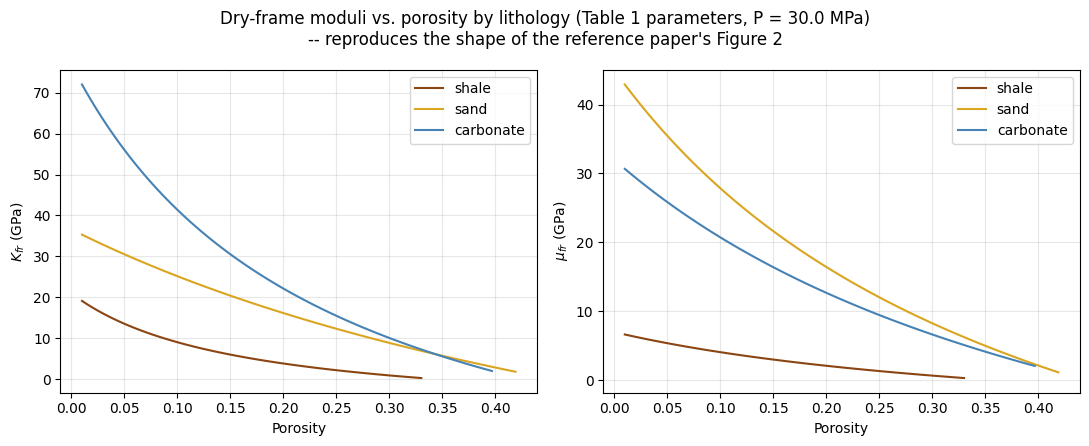

Table 1 (reproduced from the reference paper):


,phi_c,C,gamma
lithology,,,
shale,0.33,2.0,0.56
sand,0.42,6.7,0.01
carbonate,0.40,6.7,0.64


In [ ]:
P_check = 30.0  # MPa, representative mid-depth differential pressure
phi_axis = np.linspace(0.01, 0.45, 100)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
colors = {"shale": "saddlebrown", "sand": "goldenrod", "carbonate": "steelblue"}

for litho, params in LITHOLOGY_PARAMS.items():
    # pure end-member fractions
    vsh = 1.0 if litho == "shale" else 0.0
    vsand = 1.0 if litho == "sand" else 0.0
    vcarb = 1.0 if litho == "carbonate" else 0.0
    fractions = np.array([vsand, vsh, vcarb])
    Ks_l, Mus_l = vrh_average(fractions, K_MIN, MU_MIN)

    K_HM_l, Mu_HM_l = hertz_mindlin(Ks_l, Mus_l, params["phi_c"], params["C"], params["gamma"], P_check)
    phi_valid = phi_axis[phi_axis <= params["phi_c"]]
    K_fr_l, Mu_fr_l = modified_hashin_shtrikman_frame(phi_valid, params["phi_c"], Ks_l, Mus_l, K_HM_l, Mu_HM_l)

    axes[0].plot(phi_valid, K_fr_l, label=litho, color=colors[litho])
    axes[1].plot(phi_valid, Mu_fr_l, label=litho, color=colors[litho])

for ax, ylabel in zip(axes, [r"$K_{fr}$ (GPa)", r"$\mu_{fr}$ (GPa)"]):
    ax.set_xlabel("Porosity")
    ax.set_ylabel(ylabel)
    ax.legend()
    ax.grid(alpha=0.3)

fig.suptitle(f"Dry-frame moduli vs. porosity by lithology (Table 1 parameters, P = {P_check} MPa)\n"
             "-- reproduces the shape of the reference paper's Figure 2")
plt.tight_layout()
plt.show()

print("Table 1 (reproduced from the reference paper):")
import pandas as pd
display(pd.DataFrame(LITHOLOGY_PARAMS).T.rename_axis("lithology"))

In [ ]:
def _smooth_random_walk(n, step_std, lo, hi, seed, start=None):
    '''A bounded random walk, used to create geologically-plausible smooth log curves.'''
    rng = np.random.default_rng(seed)
    if start is None:
        start = rng.uniform(lo, hi)
    walk = np.empty(n)
    walk[0] = np.clip(start, lo, hi)
    for i in range(1, n):
        walk[i] = np.clip(walk[i-1] + rng.normal(0, step_std), lo, hi)
    return walk


def generate_synthetic_well(well_name, n_samples, depth_start, depth_step, litho_character, seed):
    '''Generates one synthetic well: smooth VSH/VSAND/VCARB, POR, SW, PD curves, passed
    through the from-scratch rock_physics_forward_model to get exact Vp, Vs, RHO.

    Parameters
    ----------
    well_name : str, label only.
    n_samples : number of depth samples.
    depth_start : starting depth (m).
    depth_step : sample spacing (m).
    litho_character : one of "shale-dominated", "sand-dominated", "mixed", "carbonate-rich".
    seed : RNG seed (reproducibility).

    Returns
    -------
    dict of 1-D arrays: DEPTH, VSH, VSAND, VCARB, POR, SW, PD, VP, VS, RHO
    '''
    rng = np.random.default_rng(seed)
    depth = depth_start + np.arange(n_samples) * depth_step

    # --- lithology random walk, anchored around the requested "character" ---
    centers = {
        "shale-dominated":  dict(vsh=0.65, vsand=0.30, vcarb=0.05),
        "sand-dominated":   dict(vsh=0.25, vsand=0.65, vcarb=0.10),
        "mixed":            dict(vsh=0.40, vsand=0.40, vcarb=0.20),
        "carbonate-rich":   dict(vsh=0.15, vsand=0.25, vcarb=0.60),
    }[litho_character]

    vsh_raw = _smooth_random_walk(n_samples, 0.03, 0.0, 1.0, seed + 1, start=centers["vsh"])
    vsand_raw = _smooth_random_walk(n_samples, 0.03, 0.0, 1.0, seed + 2, start=centers["vsand"])
    vcarb_raw = _smooth_random_walk(n_samples, 0.02, 0.0, 1.0, seed + 3, start=centers["vcarb"])
    total = vsh_raw + vsand_raw + vcarb_raw
    vsh, vsand, vcarb = vsh_raw/total, vsand_raw/total, vcarb_raw/total

    # --- porosity: mild compaction trend (decreasing with depth) + local variation ---
    phi_c_eff, _, _ = effective_hm_parameters(vsand.mean(), vsh.mean(), vcarb.mean())
    phi_start = rng.uniform(0.18, 0.30)
    phi_trend = np.linspace(phi_start, phi_start * rng.uniform(0.45, 0.7), n_samples)
    phi_noise = _smooth_random_walk(n_samples, 0.01, -0.05, 0.05, seed + 4, start=0.0)
    phi = np.clip(phi_trend + phi_noise, 0.02, 0.95 * phi_c_eff)

    # --- water saturation: background level + a randomly placed "pay zone" dip ---
    sw_background = rng.uniform(0.75, 1.0)
    sw = np.full(n_samples, sw_background)
    if rng.random() < 0.7:  # 70% chance of a hydrocarbon zone
        zone_len = rng.integers(n_samples // 6, n_samples // 2)
        zone_start = rng.integers(0, max(1, n_samples - zone_len))
        sw_pay = rng.uniform(0.15, 0.45)
        sw[zone_start:zone_start + zone_len] = sw_pay
    sw = np.clip(sw + rng.normal(0, 0.02, n_samples), 0.05, 1.0)

    # --- differential pressure: increases with depth (effective stress), small noise ---
    pd_start = rng.uniform(8, 15)
    pd_end = pd_start + rng.uniform(15, 30)
    pd = np.linspace(pd_start, pd_end, n_samples) + rng.normal(0, 0.8, n_samples)
    pd = np.clip(pd, 2.0, None)

    # --- forward rock-physics model: exact, noise-free Vp, Vs, RHO ---
    out = rock_physics_forward_model(vsh, vsand, vcarb, phi, sw, pd)

    return dict(
        name=well_name, DEPTH=depth, VSH=vsh, VSAND=vsand, VCARB=vcarb,
        POR=phi, SW=sw, PD=pd, VP=out["Vp"], VS=out["Vs"], RHO=out["rho"],
    )


# --- generate 30 synthetic wells, matching the paper's stated count ---
N_WELLS = 30
CHARACTERS = ["shale-dominated", "sand-dominated", "mixed", "carbonate-rich"]

synthetic_wells = []
rng_master = np.random.default_rng(2024)
for i in range(N_WELLS):
    character = CHARACTERS[i % len(CHARACTERS)]
    n_samples = int(rng_master.integers(80, 220))
    depth_start = float(rng_master.uniform(3000, 3800))
    well = generate_synthetic_well(
        well_name=f"SYN{i+1:02d}", n_samples=n_samples, depth_start=depth_start,
        depth_step=0.5, litho_character=character, seed=1000 + i,
    )
    synthetic_wells.append(well)

total_samples = sum(len(w["DEPTH"]) for w in synthetic_wells)
print(f"Generated {len(synthetic_wells)} synthetic wells, {total_samples} total depth samples.")
print(f"Example well 0: name={synthetic_wells[0]['name']}, n_samples={len(synthetic_wells[0]['DEPTH'])}")

Generated 30 synthetic wells, 4393 total depth samples.
Example well 0: name=SYN01, n_samples=113


### 8.3 Example synthetic well — full log display

A single synthetic well, shown the way a log analyst would display it: input curves on the left, forward-modeled outputs on the right.

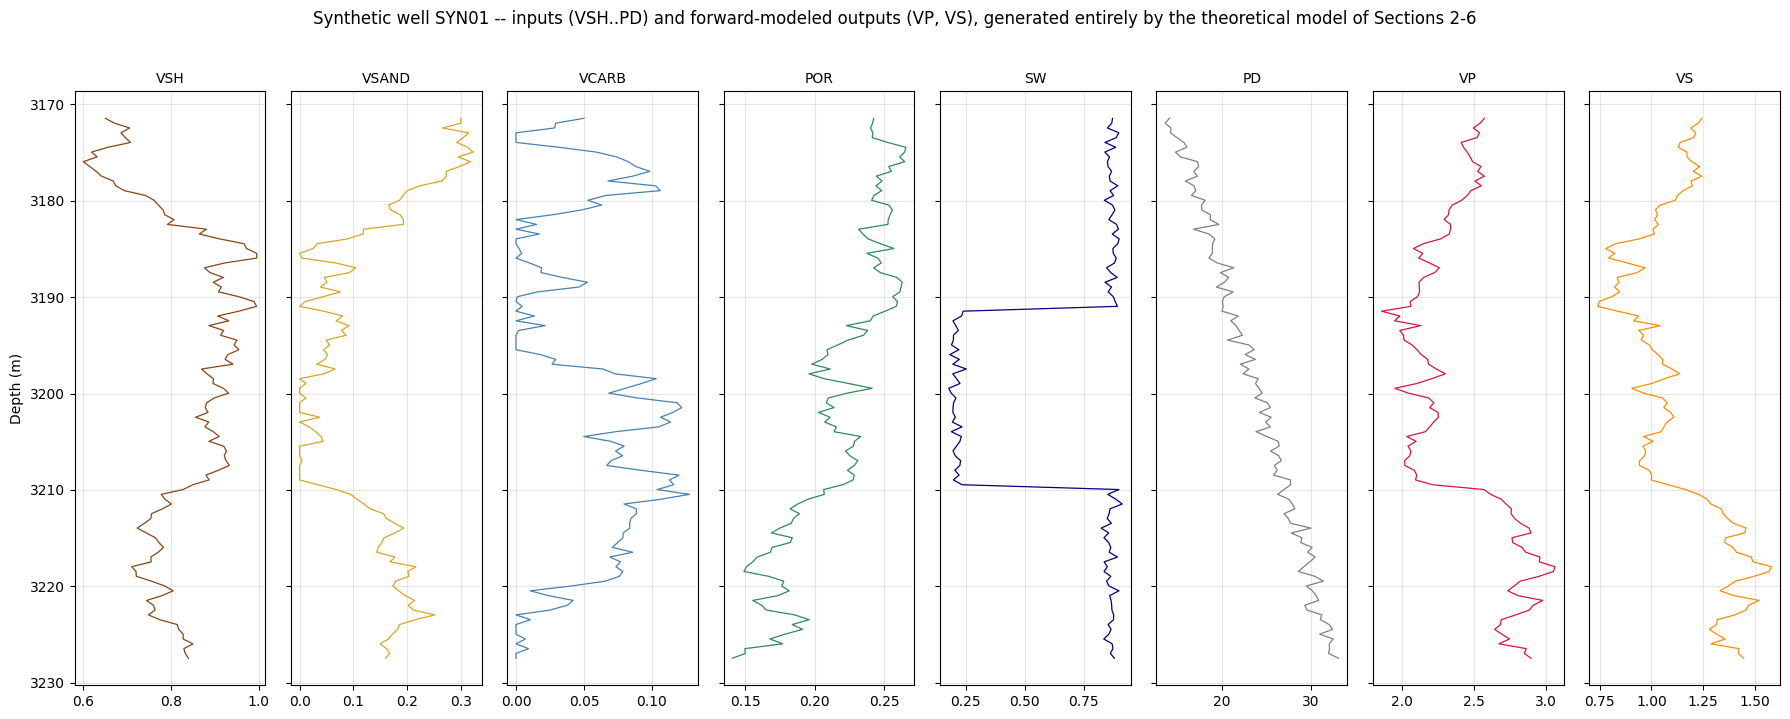

In [ ]:
example = synthetic_wells[0]
fig, axes = plt.subplots(1, 8, figsize=(18, 7), sharey=True)
tracks = ["VSH", "VSAND", "VCARB", "POR", "SW", "PD", "VP", "VS"]
colors_track = ["saddlebrown", "goldenrod", "steelblue", "seagreen", "navy", "gray", "crimson", "darkorange"]
for ax, col, c in zip(axes, tracks, colors_track):
    ax.plot(example[col], example["DEPTH"], color=c, linewidth=0.9)
    ax.set_title(col, fontsize=10)
    ax.grid(alpha=0.3)
axes[0].invert_yaxis()
axes[0].set_ylabel("Depth (m)")
fig.suptitle(f"Synthetic well {example['name']} -- inputs (VSH..PD) and forward-modeled "
             "outputs (VP, VS), generated entirely by the theoretical model of Sections 2-6", y=1.02)
plt.tight_layout()
plt.show()

### 8.4 Assembling the full synthetic dataset (same 10-column schema as the real well data)

In [ ]:
COLUMN_ORDER = ["DEPTH", "VSH", "VSAND", "VCARB", "POR", "SW", "PD", "VP", "VS", "RHO"]

synthetic_arrays = {}
for well in synthetic_wells:
    arr = np.column_stack([well[c] for c in COLUMN_ORDER])
    synthetic_arrays[well["name"]] = arr

# concatenate into one big table for easy exploration (with a well-id column for grouping)
rows = []
for well in synthetic_wells:
    n = len(well["DEPTH"])
    row_block = np.column_stack([well[c] for c in COLUMN_ORDER])
    rows.append(np.column_stack([row_block, np.full(n, well["name"])]))
synthetic_full = np.vstack(rows)

synthetic_df = pd.DataFrame(synthetic_full, columns=COLUMN_ORDER + ["WELL"])
for c in COLUMN_ORDER:
    synthetic_df[c] = synthetic_df[c].astype(float)

print(f"Synthetic dataset shape: {synthetic_df.shape}")
synthetic_df.head()

Synthetic dataset shape: (4393, 11)


,DEPTH,VSH,VSAND,VCARB,POR,SW,PD,VP,VS,RHO,WELL
0,3171.458561,0.650000,0.300000,0.050000,0.242566,0.871740,14.141977,2.574147,1.244510,2.219252,SYN01
1,3171.958561,0.670762,0.299987,0.029251,0.241838,0.868577,13.659805,2.545345,1.225757,2.218233,SYN01
2,3172.458561,0.705431,0.266146,0.028424,0.240347,0.850175,14.313010,2.497532,1.190169,2.217940,SYN01
3,3172.958561,0.685623,0.314377,0.000000,0.241974,0.898324,14.274949,2.540146,1.214321,2.217192,SYN01
4,3173.458561,0.695590,0.304410,0.000000,0.241606,0.887646,14.978998,2.523601,1.204846,2.216785,SYN01


In [ ]:
import os
os.makedirs("data", exist_ok=True)

# save one .npy per synthetic well (same schema/format as the real 19A/BT2/SR/F1B files)
for name, arr in synthetic_arrays.items():
    np.save(f"data/{name}.npy", arr)

# also save the combined table as CSV for easy inspection in any tool
synthetic_df.to_csv("data/synthetic_wells_combined.csv", index=False)

print(f"Saved {len(synthetic_arrays)} synthetic well .npy files and one combined CSV to ./data/")
print("Column order in each .npy file:", COLUMN_ORDER)

Saved 30 synthetic well .npy files and one combined CSV to ./data/
Column order in each .npy file: ['DEPTH', 'VSH', 'VSAND', 'VCARB', 'POR', 'SW', 'PD', 'VP', 'VS', 'RHO']



<a id="sec9"></a>
## 9. Exploring the Synthetic Dataset

### 9.1 Distributions of every curve, across all 30 synthetic wells


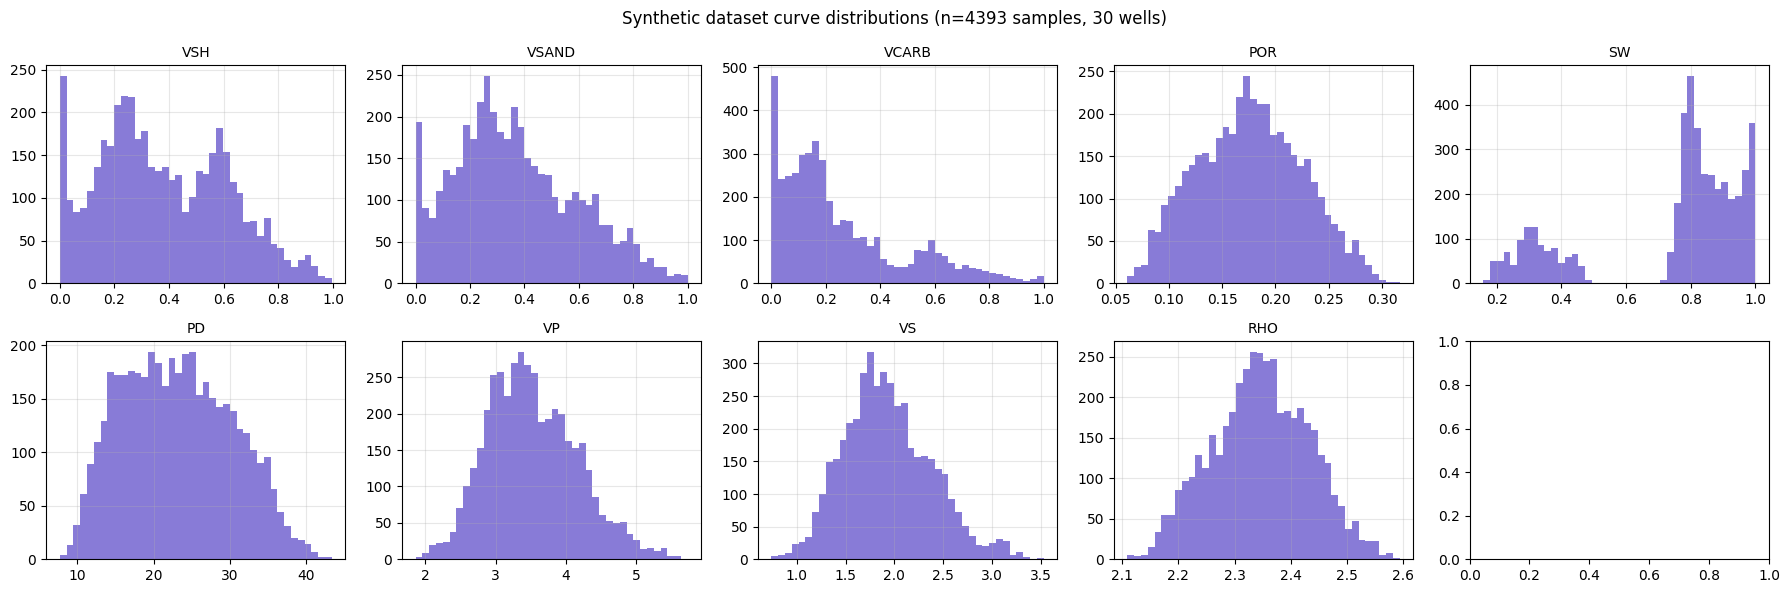

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(18, 6))
axes = axes.ravel()
for ax, col in zip(axes, COLUMN_ORDER[1:]):
    ax.hist(synthetic_df[col], bins=40, color="slateblue", alpha=0.8)
    ax.set_title(col, fontsize=10)
    ax.grid(alpha=0.3)
plt.suptitle(f"Synthetic dataset curve distributions (n={len(synthetic_df)} samples, {N_WELLS} wells)")
plt.tight_layout()
plt.show()

### 9.2 Vp and Vs vs. porosity, colored by dominant lithology

A classic rock-physics cross-plot: velocity should decrease with increasing porosity (softer frame) and vary systematically by lithology, since each end-member has different solid moduli and Hertz-Mindlin parameters (Table 1).

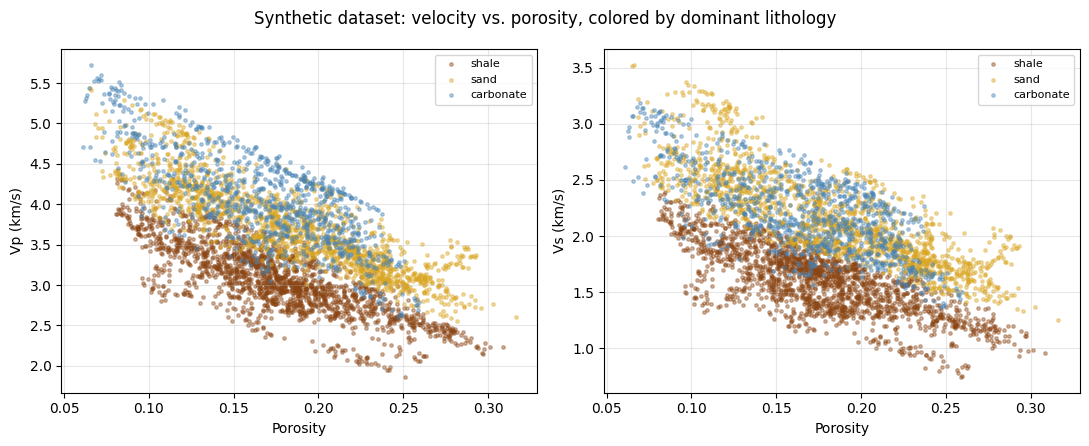

In [ ]:
dominant_litho = np.where(
    synthetic_df["VCARB"] > 0.4, "carbonate",
    np.where(synthetic_df["VSH"] > synthetic_df["VSAND"], "shale", "sand"),
)
synthetic_df["dominant_lithology"] = dominant_litho

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for litho, color in zip(["shale", "sand", "carbonate"], ["saddlebrown", "goldenrod", "steelblue"]):
    mask = synthetic_df["dominant_lithology"] == litho
    axes[0].scatter(synthetic_df.loc[mask, "POR"], synthetic_df.loc[mask, "VP"],
                     s=6, alpha=0.4, label=litho, color=color)
    axes[1].scatter(synthetic_df.loc[mask, "POR"], synthetic_df.loc[mask, "VS"],
                     s=6, alpha=0.4, label=litho, color=color)
for ax, ylabel in zip(axes, ["Vp (km/s)", "Vs (km/s)"]):
    ax.set_xlabel("Porosity")
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.suptitle("Synthetic dataset: velocity vs. porosity, colored by dominant lithology")
plt.tight_layout()
plt.show()

### 9.3 Effect of water saturation on Vp and Vs (fluid sensitivity, revisited across the whole dataset)

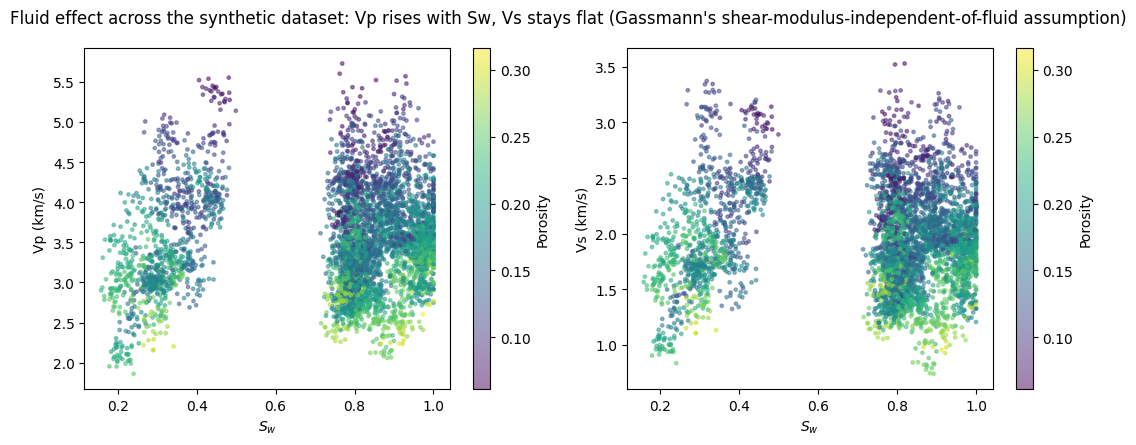

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sc0 = axes[0].scatter(synthetic_df["SW"], synthetic_df["VP"], c=synthetic_df["POR"],
                       cmap="viridis", s=6, alpha=0.5)
axes[0].set_xlabel(r"$S_w$")
axes[0].set_ylabel("Vp (km/s)")
plt.colorbar(sc0, ax=axes[0], label="Porosity")

sc1 = axes[1].scatter(synthetic_df["SW"], synthetic_df["VS"], c=synthetic_df["POR"],
                       cmap="viridis", s=6, alpha=0.5)
axes[1].set_xlabel(r"$S_w$")
axes[1].set_ylabel("Vs (km/s)")
plt.colorbar(sc1, ax=axes[1], label="Porosity")

plt.suptitle("Fluid effect across the synthetic dataset: Vp rises with Sw, Vs stays flat "
             "(Gassmann's shear-modulus-independent-of-fluid assumption)")
plt.tight_layout()
plt.show()

### 9.4 Vp/Vs ratio — a classic lithology/fluid discriminator

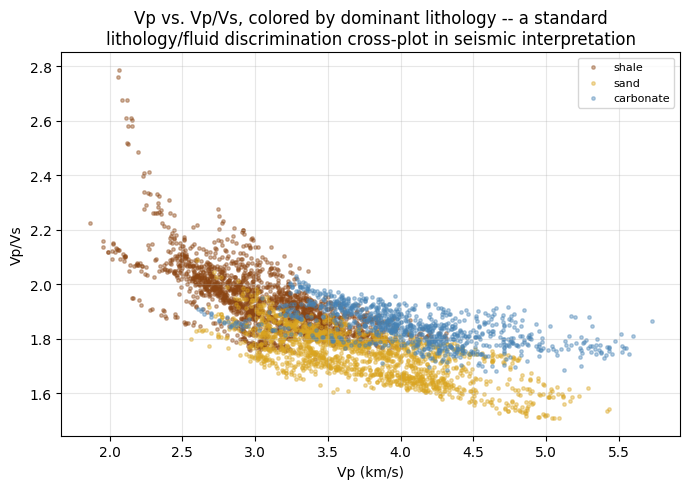

In [ ]:
synthetic_df["VPVS"] = synthetic_df["VP"] / synthetic_df["VS"]

fig, ax = plt.subplots(figsize=(7, 5))
for litho, color in zip(["shale", "sand", "carbonate"], ["saddlebrown", "goldenrod", "steelblue"]):
    mask = synthetic_df["dominant_lithology"] == litho
    ax.scatter(synthetic_df.loc[mask, "VP"], synthetic_df.loc[mask, "VPVS"],
               s=6, alpha=0.4, label=litho, color=color)
ax.set_xlabel("Vp (km/s)")
ax.set_ylabel("Vp/Vs")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
ax.set_title("Vp vs. Vp/Vs, colored by dominant lithology -- a standard\nlithology/fluid discrimination cross-plot in seismic interpretation")
plt.tight_layout()
plt.show()


<a id="sec11"></a>
## 11. References

1. Jiang, L., Castagna, J. P., Russell, B., and Guillen, P. (2020). *Rock physics modeling
   using machine learning*. SEG International Exposition and 90th Annual Meeting,
   pp. 2530–2534. DOI: 10.1190/segam2020-3427097.1
2. Gassmann, F. (1951). Über die Elastizität poröser Medien. *Vierteljahrsschrift der
   Naturforschenden Gesellschaft in Zürich*, 96, 1–23.
3. Mindlin, R. D. (1949). Compliance of elastic bodies in contact. *Journal of Applied
   Mechanics*, 16, 259–268.
4. Walton, K. (1987). The effective elastic moduli of a random packing of spheres. *Journal
   of the Mechanics and Physics of Solids*, 35(2), 213–226.
5. Bachrach, R., and Avseth, P. (2008). Rock physics modeling of unconsolidated sands:
   Accounting for nonuniform contacts and heterogeneous stress fields in the effective
   media approximation with applications to hydrocarbon exploration. *Geophysics*, 73(6),
   E197–E209.
6. Hill, R. (1952). The elastic behaviour of a crystalline aggregate. *Proceedings of the
   Physical Society A*, 65(5), 349–354.
7. Batzle, M., and Wang, Z. (1992). Seismic properties of pore fluids. *Geophysics*, 57(11),
   1396–1408.
8. Mavko, G., Mukerji, T., and Dvorkin, J. (2009). *The Rock Physics Handbook: Tools for
   Seismic Analysis of Porous Media*, 2nd ed. Cambridge University Press.
9. Grana, D. (2016). Bayesian linearized rock-physics inversion. *Geophysics*, 81(6),
   D625–D641. DOI: 10.1190/geo2016-0161.1
10. Ruiz, F. J. (2009). *Porous grain model and equivalent elastic medium approach for
    predicting effective elastic properties of sedimentary rocks*. Ph.D. dissertation,
    Stanford University.
